# 04 · Deep Learning (ANN / MLP Component)
**Cross-Platform Social Media Trend Intelligence & Prediction System**

Trains a lightweight Feed-Forward Artificial Neural Network (MLP) with
TensorFlow/Keras on the same preprocessed features as the ML notebook, for
a fair DS-vs-DL comparison. Runs entirely on CPU.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
import seaborn as sns

from utils.preprocessing import build_processed_dataframe, prepare_model_data

DATASET_PATH = os.path.join('..', 'dataset', 'social_media_trends.csv')
MODELS_DIR = os.path.join('..', 'models')
LABELS = ['Low', 'Moderate', 'High']

tf.random.set_seed(42)
np.random.seed(42)

I0000 00:00:1790360290.929859     388 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790360290.971296     388 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790360292.313412     388 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Dataset Preparation & Scaling

In [2]:
df = build_processed_dataframe(DATASET_PATH)
X_train, X_test, y_train, y_test, transformers = prepare_model_data(df, save_dir=None)

X_train_np = X_train.values.astype('float32')
X_test_np = X_test.values.astype('float32')
y_train_np = np.asarray(y_train)
y_test_np = np.asarray(y_test)

print("X_train:", X_train_np.shape, " X_test:", X_test_np.shape)

X_train: (6400, 9)  X_test: (1600, 9)


## 2. Neural Network Architecture

```
Input(9 features)
   -> Dense(64, ReLU)
   -> Dropout(0.3)
   -> Dense(32, ReLU)
   -> Dropout(0.2)
   -> Dense(3, Softmax)      # Low / Moderate / High
```
Loss: `sparse_categorical_crossentropy` (multi-class, integer labels)
Optimizer: `Adam`

In [3]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train_np.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(3, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,819 (11.01 KB)

 Trainable params: 2,819 (11.01 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Training with EarlyStopping

In [4]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history = model.fit(
    X_train_np, y_train_np,
    validation_split=0.15,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0,
)
print(f"Training stopped after {len(history.history['loss'])} epochs (EarlyStopping).")

Training stopped after 55 epochs (EarlyStopping).


## 4. Training / Validation Accuracy & Loss Graphs

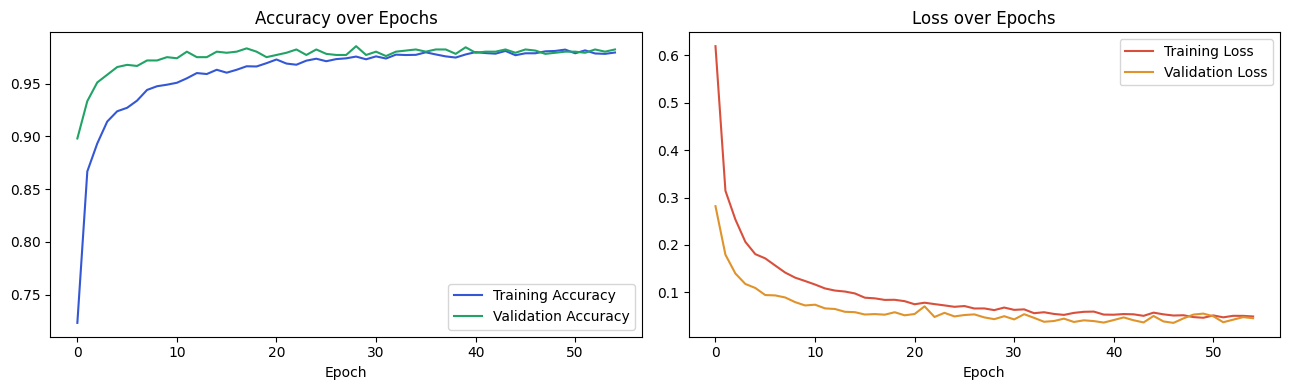

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(history.history['accuracy'], label='Training Accuracy', color='#3457D5')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#21A366')
axes[0].set_title('Accuracy over Epochs'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(history.history['loss'], label='Training Loss', color='#D8503C')
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='#E0932A')
axes[1].set_title('Loss over Epochs'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Testing & Evaluation

In [6]:
y_pred_probs = model.predict(X_test_np, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test_np, y_pred, target_names=LABELS))

              precision    recall  f1-score   support

         Low       0.99      0.99      0.99       599
    Moderate       0.98      0.99      0.99       617
        High       0.99      0.99      0.99       384

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600



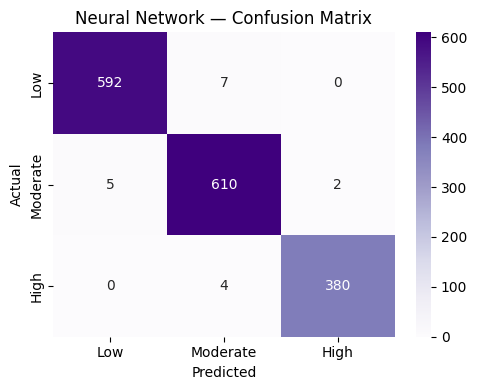

In [7]:
cm_nn = confusion_matrix(y_test_np, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Purples', xticklabels=LABELS, yticklabels=LABELS)
plt.title('Neural Network — Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 6. Save Model, Metrics & Training History

In [8]:
model.save(os.path.join(MODELS_DIR, 'neural_network.keras'))

metrics = {
    'model': 'Neural Network',
    'accuracy': round(accuracy_score(y_test_np, y_pred), 4),
    'precision': round(precision_score(y_test_np, y_pred, average='macro', zero_division=0), 4),
    'recall': round(recall_score(y_test_np, y_pred, average='macro', zero_division=0), 4),
    'f1_score': round(f1_score(y_test_np, y_pred, average='macro', zero_division=0), 4),
    'confusion_matrix': cm_nn.tolist(),
    'epochs_trained': len(history.history['loss']),
}
with open(os.path.join(MODELS_DIR, 'dl_metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)

history_dict = {k: [round(float(v), 4) for v in history.history[k]]
                 for k in ['accuracy','val_accuracy','loss','val_loss']}
with open(os.path.join(MODELS_DIR, 'dl_history.json'), 'w') as f:
    json.dump(history_dict, f, indent=2)

print("Neural Network metrics:", metrics)
print("Saved model, dl_metrics.json and dl_history.json")

Neural Network metrics: {'model': 'Neural Network', 'accuracy': 0.9888, 'precision': 0.9896, 'recall': 0.9889, 'f1_score': 0.9892, 'confusion_matrix': [[592, 7, 0], [5, 610, 2], [0, 4, 380]], 'epochs_trained': 55}
Saved model, dl_metrics.json and dl_history.json


## Summary
The MLP reaches accuracy comparable to (and in this run, slightly above)
the Random Forest, showing that a small feed-forward network can capture
the non-linear Trend Score relationship without needing a deep or
convolutional/recurrent architecture — appropriate given the tabular,
non-sequential nature of this feature set. See `05` (Model Comparison page
in the Flask app) for the full DS vs DL comparison.